<a href="https://colab.research.google.com/github/alyPoint/CEFET---Processamento-de-Sinais-I-140826/blob/main/Pratica_6/DSP_1_PRATICA_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Questão 1**

### **Letra a**

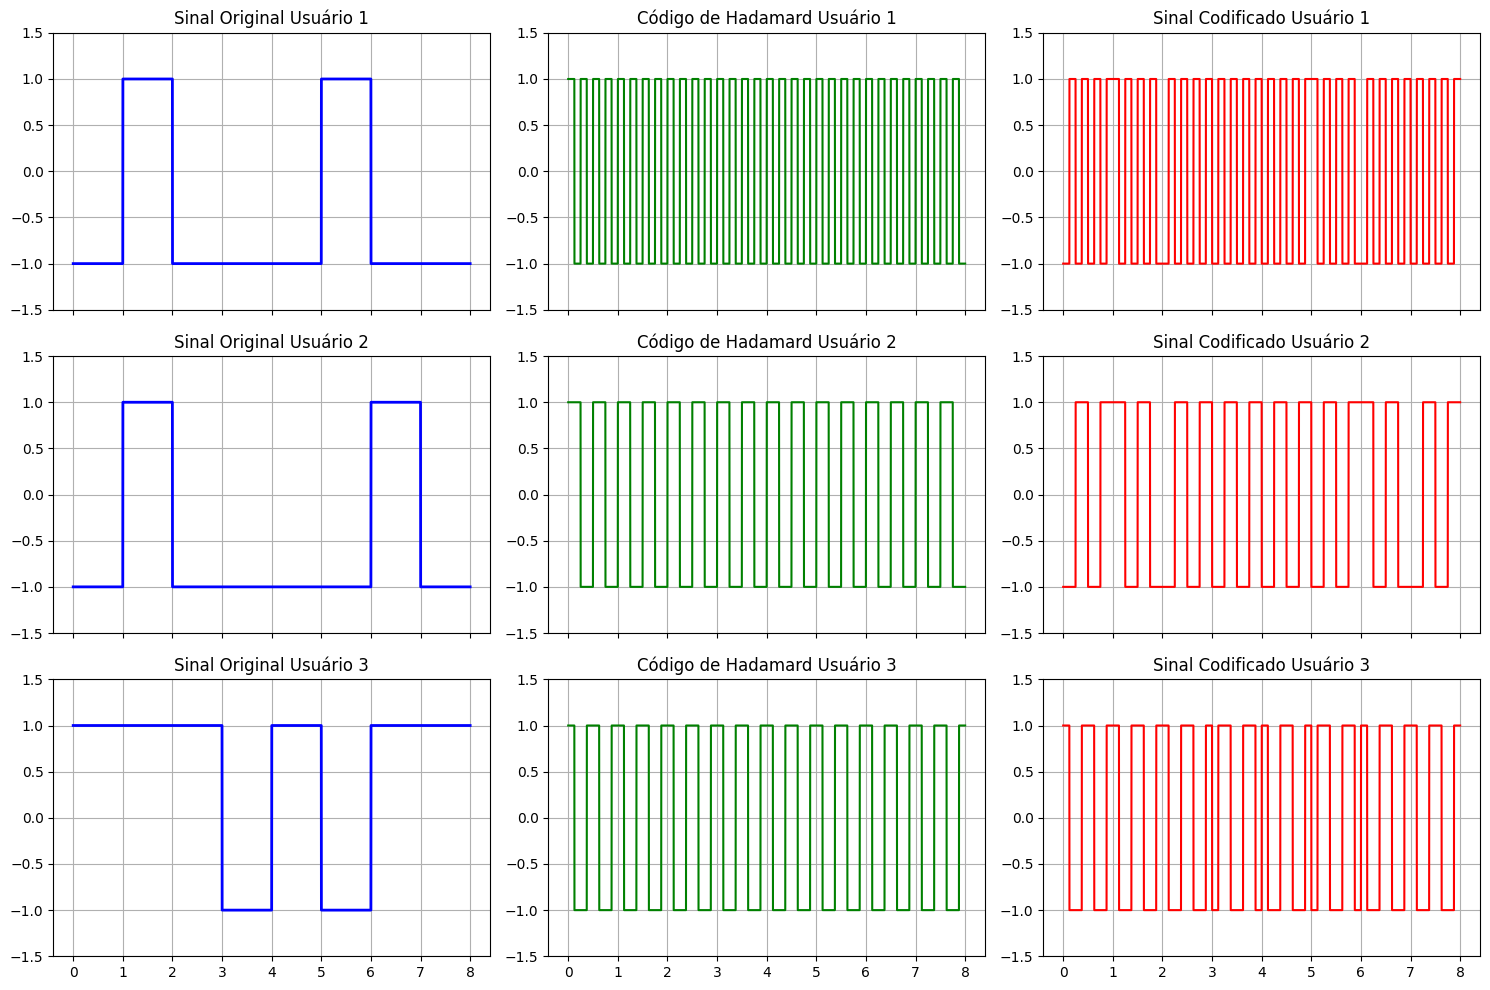

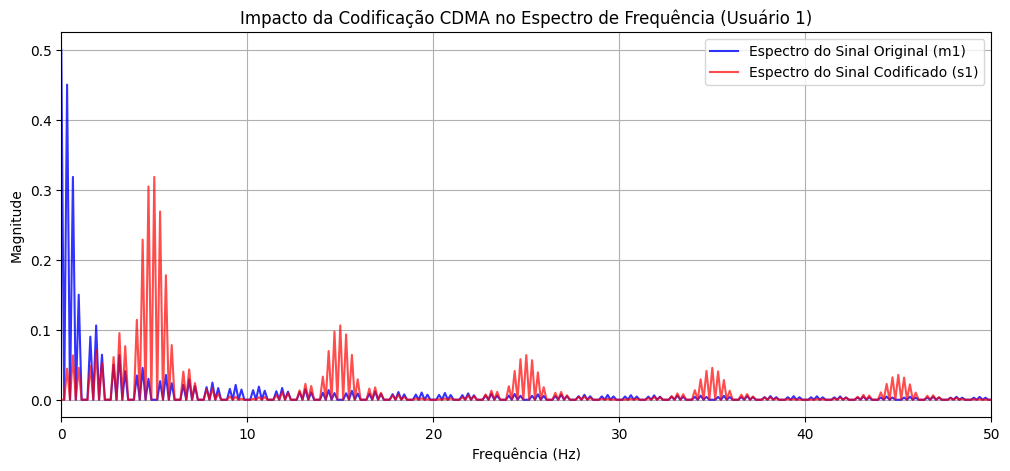

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

# 1. Configurações Iniciais e Geração de Dados
np.random.seed(42)  # Para reprodutibilidade
N = 8               # Comprimento da sequência de bits e do código de Hadamard
fs = 1000           # Frequência de amostragem para visualização do espectro (Hz)
samples_per_bit = 100  # Amostras por bit para suavizar os gráficos temporais

# Gerando mensagens originais m[n] em {-1, 1} para 3 usuários
m1 = np.random.choice([-1, 1], N)
m2 = np.random.choice([-1, 1], N)
m3 = np.random.choice([-1, 1], N)

# 2. Geração dos Códigos de Hadamard
# A função hadamard(8) gera uma matriz 8x8 ortogonal
H = hadamard(N)
c1 = H[1, :]  # Código do Usuário 1 (Linha 1)
c2 = H[2, :]  # Código do Usuário 2 (Linha 2)
c3 = H[3, :]  # Código do Usuário 3 (Linha 3)

# 3. Codificação CDMA (Espalhamento)
# Cada bit do usuário é multiplicado por todo o seu código de Hadamard de 8 chips
s1 = np.kron(m1, c1)
s2 = np.kron(m2, c2)
s3 = np.kron(m3, c3)

# 4. Preparação dos Sinais para Gráficos (Forma de Onda Quadrada)
m1_upsampled = np.repeat(m1, N * samples_per_bit)
m2_upsampled = np.repeat(m2, N * samples_per_bit)
m3_upsampled = np.repeat(m3, N * samples_per_bit)

c1_upsampled = np.tile(np.repeat(c1, samples_per_bit), N)
c2_upsampled = np.tile(np.repeat(c2, samples_per_bit), N)
c3_upsampled = np.tile(np.repeat(c3, samples_per_bit), N)

s1_upsampled = np.repeat(s1, samples_per_bit)
s2_upsampled = np.repeat(s2, samples_per_bit)
s3_upsampled = np.repeat(s3, samples_per_bit)

# Vetor de tempo para o sinal espalhado (N * N chips no total)
t = np.linspace(0, N, len(s1_upsampled))

# 5. Visualização no Domínio do Tempo
fig, axs = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
signals = [
    (m1_upsampled, c1_upsampled, s1_upsampled, 'Usuário 1'),
    (m2_upsampled, c2_upsampled, s2_upsampled, 'Usuário 2'),
    (m3_upsampled, c3_upsampled, s3_upsampled, 'Usuário 3')
]

for i, (m, c, s, name) in enumerate(signals):
    axs[i, 0].plot(t, m, 'b', linewidth=2)
    axs[i, 0].set_title(f'Sinal Original {name}')
    axs[i, 0].grid(True)
    axs[i, 0].set_ylim(-1.5, 1.5)

    axs[i, 1].plot(t, c, 'g', linewidth=1.5)
    axs[i, 1].set_title(f'Código de Hadamard {name}')
    axs[i, 1].grid(True)
    axs[i, 1].set_ylim(-1.5, 1.5)

    axs[i, 2].plot(t, s, 'r', linewidth=1.5)
    axs[i, 2].set_title(f'Sinal Codificado {name}')
    axs[i, 2].grid(True)
    axs[i, 2].set_ylim(-1.5, 1.5)

plt.tight_layout()
plt.show()

# 6. Cálculo e Visualização do Espectro (Frequência)
def calcular_espectro(sinal, fs):
    N_fft = len(sinal)
    freq = np.fft.fftfreq(N_fft, d=1/fs)
    espectro = np.abs(np.fft.fft(sinal)) / N_fft
    # Retorna apenas a metade positiva do espectro
    half = N_fft // 2
    return freq[:half], espectro[:half]

f_m1, E_m1 = calcular_espectro(m1_upsampled, fs)
f_s1, E_s1 = calcular_espectro(s1_upsampled, fs)

plt.figure(figsize=(12, 5))
plt.plot(f_m1, E_m1, 'b', label='Espectro do Sinal Original (m1)', alpha=0.8)
plt.plot(f_s1, E_s1, 'r', label='Espectro do Sinal Codificado (s1)', alpha=0.7)
plt.title('Impacto da Codificação CDMA no Espectro de Frequência (Usuário 1)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 50)  # Limitando o eixo X para melhor visualização das baixas frequências
plt.legend()
plt.grid(True)
plt.show()


**Comentários**


Análise e Impacto da Codificação no Espectro

Mudança drástica no comportamento do sinal ao passar do domínio do tempo para o de frequências:
1. Espalhamento Espectral (Spread Spectrum): O sinal original m[n] possui uma taxa de variação lenta (baixa frequência), pois cada bit dura um tempo longo. No espectro, isso se traduz em uma alta concentração de energia acumulada próxima de 0 Hz (faixa estreita).
2. Efeito do Código de Hadamard: O código de Hadamard possui transições muito mais rápidas (alta frequência de chips). Ao multiplicar o sinal original pelo código, a taxa de transição do sinal resultante s[n] aumenta em 8 vezes.
3. Impacto no Espectro: No gráfico de frequências, você notará que a energia concentrada e de alta magnitude do sinal original "espalha-se" por uma banda muito mais larga, reduzindo drasticamente a sua densidade espectral de potência máxima (o pico do gráfico vermelho é muito menor que o do azul).


### **Letra b**

### **Letra d**

### **Letra f**

## **Questão 2**

## **Questão 3**

### **Letra b**

### **Letra c**

## **Questão 4**

### **Letra a**

### **Letra b**

### **Letra c**

### **Letra d**

### **Letra e**